# Ethane cracking furnace coking: physics vs ML vs hybrid

**Goal.** Predict when a furnace must be decoked (run length) and what that prediction is worth in €.
We compare three models on the same sparse, noisy data: physics-only, ML-only and a hybrid.

**Honesty rule for this notebook.** The "plant" is synthetic. A hidden-truth simulator produces the data,
and the models never see its parameters. That is the only way to measure which model is right.
Values are illustrative and not from any real plant, client or employer.

*Author: Madhushree Bharadwaj, process simulation and OTS engineer.*

## Step 1 · The physics core: one radiant coil

The coil model is reused from my **Cracking Furnace Trainer** (`src/engine.js`), ported to Python in `coil.py`.

How it works, in four lines:
1. One pass = one tube, cut into 40 cells. Ethane + steam enter at 640 °C.
2. Every cell receives the same heat from the firebox (uniform heat flux).
3. Three reactions from **Sundaram & Froment (1977)** convert ethane, mainly to ethylene + hydrogen.
4. Gas temperature rises by *(heat in − heat used by reactions) ÷ heat capacity*.

The coil volume and heat duty are calibrated once so the design point gives **COT 850 °C at 65 % conversion**.

In [1]:
import sys; sys.path.insert(0, '.')
import coil
import matplotlib.pyplot as plt

cal = coil.calibrate()                       # find V and Q for the design point
nE0, nW0 = coil.design_flows()               # ethane and steam into one pass, mol/s
r = coil.solve_coil(nE0, nW0, cal['Q'], cal['V'], profiles=True)

print(f"Coil volume per pass : {cal['V']:.3f} m3")
print(f"Heat absorbed / pass : {cal['Q']/1e6:.2f} MW")
print(f"COT {r['cot']:.1f} C, conversion {r['X']:.1%}, "
      f"ethylene {coil.ethylene_tph(r['y']):.2f} t/h ({coil.ethylene_tph(r['y'])/coil.FEED_TPH:.1%} of feed)")

Coil volume per pass : 2.199 m3
Heat absorbed / pass : 8.63 MW
COT 850.0 C, conversion 65.0%, ethylene 16.84 t/h (52.6% of feed)


**Check against the original.** `tests/test_coil.py` runs the same five cases through the JavaScript and
the Python model. All values match to better than 1 × 10⁻⁹, so the trainer and this project share one physics core.

In [2]:
import subprocess
print(subprocess.run([sys.executable, 'tests/test_coil.py'], capture_output=True, text=True).stdout)

Calibration
OK   V (m3)                       python       2.199466   js       2.199466   diff +0.00e+00
OK   Q (W)                        python 8627605.377693   js 8627605.377693   diff +0.00e+00
OK   X at design                  python       0.650000   js       0.650000   diff +0.00e+00

Off-design cases (feed x, steam x, heat x)
OK   COT  1/1/1                   python     850.000000   js     850.000000   diff +0.00e+00
OK   X    1/1/1                   python       0.650000   js       0.650000   diff +0.00e+00
OK   COT  0.8/1/1                 python     894.732791   js     894.732791   diff +2.27e-13
OK   X    0.8/1/1                 python       0.823886   js       0.823886   diff +1.11e-16
OK   COT  1/0.7/1                 python     852.170998   js     852.170998   diff +0.00e+00
OK   X    1/0.7/1                 python       0.665661   js       0.665661   diff +0.00e+00
OK   COT  1/1/1.05                python     858.737997   js     858.737997   diff +0.00e+00
OK   X    1/1/

### Why we need the profiles, not just the outlet

Coke grows where the gas is **hot** and rich in **coke precursors**. Here we plot ethylene, which feeds them; the coke model in Step 2 uses butadiene. Both peak at the coil outlet.
That is why published ethane coking studies find almost no coke at the inlet and the thickest layer at the exit
(Sundaram, Van Damme & Froment, 1981). Step 2 uses these profiles to grow the coke layer.

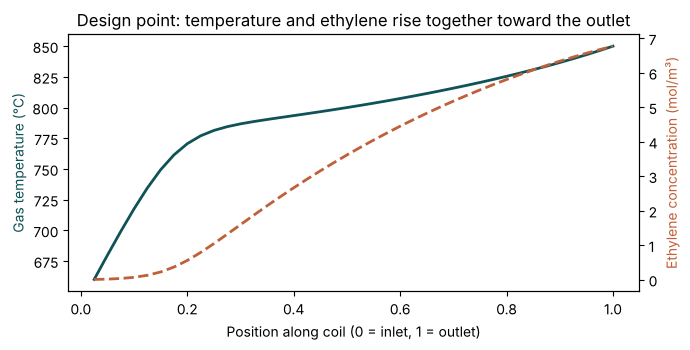

In [3]:
p = r['profiles']
fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.plot(p['z'], p['T_C'], color='#0f5257', lw=2, label='Gas temperature')
ax1.set_xlabel('Position along coil (0 = inlet, 1 = outlet)')
ax1.set_ylabel('Gas temperature (°C)', color='#0f5257')
ax2 = ax1.twinx()
ax2.plot(p['z'], p['conc_C2H4'], color='#c0603a', lw=2, ls='--', label='Ethylene')
ax2.set_ylabel('Ethylene concentration (mol/m³)', color='#c0603a')
ax1.set_title('Design point: temperature and ethylene rise together toward the outlet')
fig.tight_layout(); plt.show()

## Step 2 · Coke growth and run length (physics)

**Which coke kinetics, and why.** Sundaram, Van Damme & Froment (1981, *AIChE J.* 27, 946) tested three
coking models. They preferred **Model III: coke from the C4+ fraction** (mainly butadiene and benzene),
with the rate taken at the **gas** temperature and the **asymptotic** long-run rate.

| Item | Value | Status |
|---|---|---|
| Rate form | r_c = A_c · exp(−E_c/RT_gas) · C_precursor | from the paper (Model III) |
| E_c | 118.1 kJ/mol (28.25 kcal/mol) | published; kcal and kJ columns agree |
| A_c | 1.34 × 10³ g/(m²·s)/(mol/m³) | **calibrated** so the design case runs 60 days |
| Precursor | butadiene from S&F 1977 reactions R4 + R5 | proxy for C4+ (no benzene in this scheme) |
| Coke k, ρ | 6.46 W/m/K, 1680 kg/m³ | literature values for hard coke |
| TMT limit | 1100 °C | parameter (one Technip furnace: 1100 °C; the 1981 paper used 1030 °C) |

**Not used:** AI-search tables quoting *A = 2.11×10⁵, E = 165.4 kJ/mol via ethylene*. Those numbers do not appear
in the 1981 paper (its ethylene path, Model II, has E ≈ 208.6 kJ/mol), and the paper never models a propylene path.

**How the code works, day by day:**
1. Solve the coil at the day's feed, steam ratio and COT → temperature and butadiene in each of the 40 cells.
2. Grow coke in each cell: thickness += rate × time ÷ coke density.
3. Tube metal temperature = gas temperature + clean film drop + heat flux × thickness ÷ coke conductivity.
4. When the hottest tube point reaches 1100 °C → end of run.

A_c = 1.337e+03   heat flux = 107 kW/m2   ethylene = 15.97 t/h


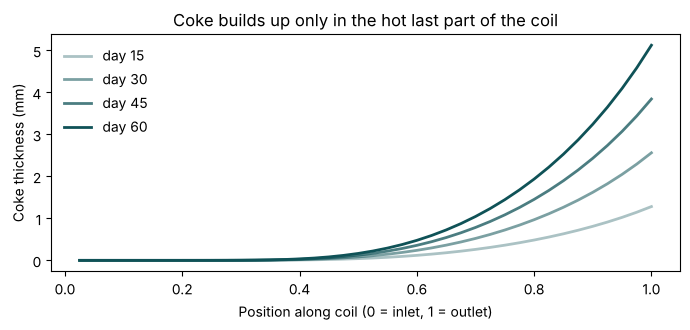

In [4]:
import coke
A_c = coke.calibrate_A_c()                   # one-time calibration to a 60-day design run
op = coke.operating_point(32, 0.32, 850)     # design: 32 t/h ethane, steam ratio 0.32, COT 850 C
print(f"A_c = {A_c:.3e}   heat flux = {op['q_flux']/1e3:.0f} kW/m2   ethylene = {op['ethylene_tph']:.2f} t/h")

# at constant conditions, coke thickness = rate x time / density, cell by cell
rate = [coke.coke_rate(T, C, A_c) for T, C in zip(op['prof']['T_C'], op['prof']['conc_C4H6'])]
fig, ax = plt.subplots(figsize=(7, 3.4))
for d, a in zip([15, 30, 45, 60], [0.35, 0.55, 0.75, 1.0]):
    mm = [r * 1e-3 * d * 86400 / coke.RHO_COKE * 1e3 for r in rate]
    ax.plot(op['prof']['z'], mm, color='#0f5257', alpha=a, lw=2, label=f'day {d}')
ax.set_xlabel('Position along coil (0 = inlet, 1 = outlet)'); ax.set_ylabel('Coke thickness (mm)')
ax.set_title('Coke builds up only in the hot last part of the coil'); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

Design 850 °C  run length  60.0 days   ethylene 15.97 t/h
COT 840 °C     run length 102.3 days   ethylene 15.03 t/h
COT 860 °C     run length  34.8 days   ethylene 16.80 t/h
Steam 0.28     run length  52.8 days   ethylene 15.87 t/h
Steam 0.40     run length  76.6 days   ethylene 16.11 t/h


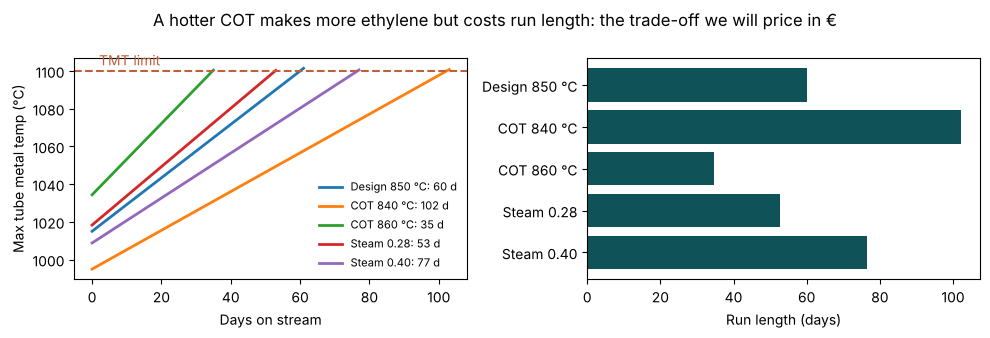

In [5]:
# run length for different operating choices (one knob at a time)
cases = [('Design 850 °C', (32, .32, 850)), ('COT 840 °C', (32, .32, 840)), ('COT 860 °C', (32, .32, 860)),
         ('Steam 0.28', (32, .28, 850)), ('Steam 0.40', (32, .40, 850))]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name, c in cases:
    run, hist = coke.simulate_run(lambda d, c=c: c, A_c)
    ax[0].plot([h['day'] for h in hist], [h['tmt_max'] for h in hist], lw=2, label=f'{name}: {run:.0f} d')
    print(f"{name:<14} run length {run:5.1f} days   ethylene {hist[0]['ethylene_tph']:.2f} t/h")
ax[0].axhline(coke.TMT_LIMIT, color='#c0603a', ls='--'); ax[0].text(2, coke.TMT_LIMIT + 3, 'TMT limit', color='#c0603a')
ax[0].set_xlabel('Days on stream'); ax[0].set_ylabel('Max tube metal temp (°C)'); ax[0].legend(frameon=False, fontsize=8)
names = [n for n, _ in cases]; runs = [coke.simulate_run(lambda d, c=c: c, A_c)[0] for _, c in cases]
ax[1].barh(names, runs, color='#0f5257'); ax[1].set_xlabel('Run length (days)'); ax[1].invert_yaxis()
fig.suptitle('A hotter COT makes more ethylene but costs run length: the trade-off we will price in €')
fig.tight_layout(); plt.show()

**What this shows.** +10 °C on COT gives about 5 % more ethylene but cuts the run from 60 to about 35 days.
More dilution steam lengthens the run. This trade-off is what the € value in a later step will price.

**Limitations, stated plainly.**
- The 5-reaction molecular scheme over-predicts butadiene (about 6 wt % vs 1–3 wt % typical). For the coke model
  only its *shape and trend* matter, because A_c absorbs the absolute level.
- The rate uses gas temperature, as in the 1981 paper. The initial fast (catalytic) coking is ignored.
- Coke does not yet narrow the tube (no pressure-drop or residence-time effect), and heat flux is uniform.
- The 60-day design run length is a calibration choice, not a measured value.

## Step 3 · The hidden-truth plant and its sparse data

**The problem with real data:** it never tells you the right answer. So we build a "true" furnace
(`plant_truth.py`), run it for 50 campaigns, and record **only what a real plant records**.
The models in Step 4 see the records, never the truth.

**What a real plant records, and so do we:**

| Record | How often | Noise | File |
|---|---|---|---|
| Feed, steam ratio, COT, coil inlet pressure (DCS daily averages) | daily | small | `dcs_daily.csv` |
| Propane in feed (lab sample) | weekly | ±0.3 mol % | `dcs_daily.csv` (`propane_lab`) |
| Hottest tube metal temperature (pyrometer survey) | **weekly** | ±8 K noise + ±6 K survey bias | `pyrometer_weekly.csv` |
| Run length (day of decoke) | once per campaign | exact | `runs.csv` |

30 campaigns form the **history** (training pool) and 20 more are held back as the **test set**.

**Why the truth must differ from our physics model.** If the truth were `coke.py` with other numbers,
the hybrid would win by construction and a reviewer would call it rigged. So the truth has effects
the physics model does not. Only the first three change the run length; tube narrowing and the biased
pyrometer change only what is measured. And the truth still shares the physics model's chemistry, uniform
heat flux and 1,100 °C decoke trigger, so this is a test of a *structurally good* physics model; real plants
differ more. The propane effect is also injected in a form the parameter hybrid can fit easily.

| Effect in the truth | Physics model (`coke.py`) | Why it is realistic |
|---|---|---|
| Fast initial coking in the first days | asymptotic rate only | Sundaram et al. (1981): rates "initially high", then asymptotic |
| Feed propane 0.5–4 % raises coking | assumes pure ethane | ethane feeds carry some propane |
| E = 128 kJ/mol, k_coke = 5.6 W/m/K, film drop 172 K | 118.1, 6.46, 165 | inside the spread of published values |
| Coke narrows the tube → inlet pressure rises | ignored | pressure drop is a known coking signal |
| Biased, noisy weekly pyrometer | n/a | handheld surveys vary with emissivity and angle |

Shared with the physics model: the gas-phase chemistry (coil.py). That is the realistic case: cracking kinetics are
well known; coking is where the uncertainty sits.

Data is generated once with `python3 plant_truth.py` (about 1 minute).

In [6]:
import pandas as pd, numpy as np
H = {f: pd.read_csv(f'data/history/{f}.csv') for f in ['dcs_daily', 'pyrometer_weekly', 'runs']}
T = {f: pd.read_csv(f'data/test/{f}.csv') for f in ['dcs_daily', 'pyrometer_weekly', 'runs']}
print(f"History: {len(H['runs'])} campaigns, {len(H['dcs_daily'])} DCS days, {len(H['pyrometer_weekly'])} pyrometer readings")
print(f"Test:    {len(T['runs'])} campaigns, {len(T['dcs_daily'])} DCS days, {len(T['pyrometer_weekly'])} pyrometer readings")
print(f"Run length in history: {H['runs'].run_length_days.min():.0f}-{H['runs'].run_length_days.max():.0f} days, "
      f"mean {H['runs'].run_length_days.mean():.0f}")
H['dcs_daily'].head(8)

History: 30 campaigns, 1812 DCS days, 263 pyrometer readings
Test:    20 campaigns, 1388 DCS days, 202 pyrometer readings
Run length in history: 31-110 days, mean 59


,run_id,day,feed_tph,steam_ratio,cot_c,cip_bara,propane_lab
0,101-00,0,28.174,0.3330,858.40,2.758,NaN
1,101-00,1,33.041,0.3311,857.63,3.094,NaN
2,101-00,2,32.637,0.3316,859.61,3.075,NaN
3,101-00,3,33.020,0.3333,859.93,3.135,0.023
4,101-00,4,32.839,0.3359,858.95,3.122,NaN
5,101-00,5,32.675,0.3335,858.74,3.083,NaN
6,101-00,6,32.963,0.3309,858.65,3.107,NaN
7,101-00,7,27.593,0.3385,860.08,2.789,NaN


### One campaign, as the plant sees it and as the truth is

The grey line is the **true** hottest tube temperature (from the hidden file, shown here only to explain).
The dots are what the plant actually knows: one noisy pyrometer reading per week.
That gap between line and dots is what makes this a sparse-data problem.

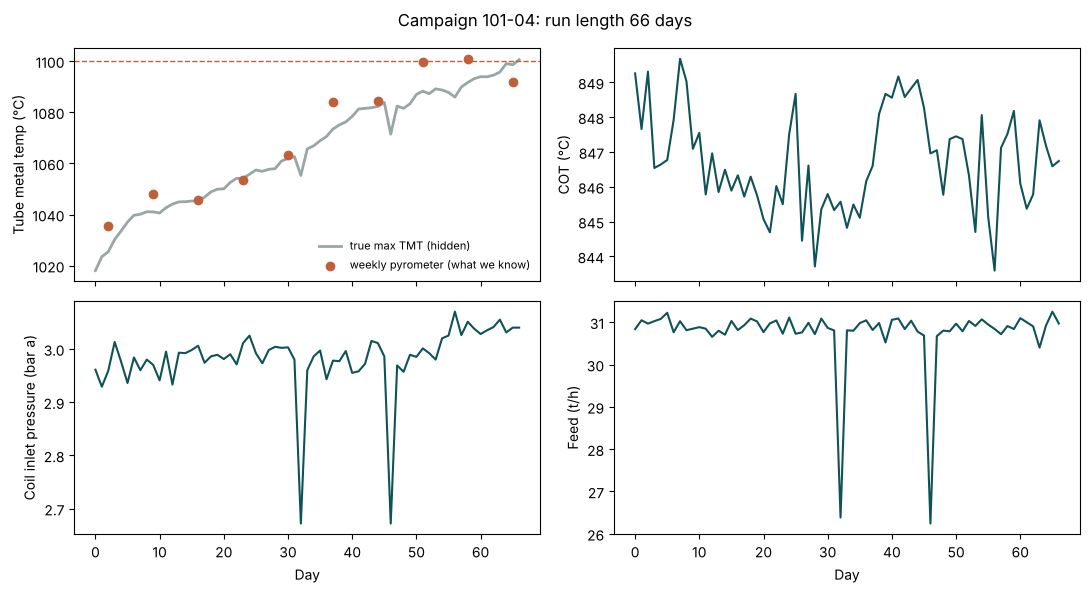

In [7]:
truth = pd.read_csv('data/hidden/history_true_daily.csv')      # audit view only: models never read this
rid = H['runs'].run_id.iloc[4]
d, p, t = H['dcs_daily'][H['dcs_daily'].run_id == rid], H['pyrometer_weekly'][H['pyrometer_weekly'].run_id == rid], truth[truth.run_id == rid]
fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
ax[0,0].plot(t.day, t.tmt_max, color='#9aa5a6', lw=2, label='true max TMT (hidden)')
ax[0,0].scatter(p.day, p.tmt_max_meas, color='#c0603a', zorder=3, label='weekly pyrometer (what we know)')
ax[0,0].axhline(1100, color='#c0603a', ls='--', lw=1); ax[0,0].set_ylabel('Tube metal temp (°C)'); ax[0,0].legend(frameon=False, fontsize=8)
ax[0,1].plot(d.day, d.cot_c, color='#0f5257'); ax[0,1].set_ylabel('COT (°C)')
ax[1,0].plot(d.day, d.cip_bara, color='#0f5257'); ax[1,0].set_ylabel('Coil inlet pressure (bar a)'); ax[1,0].set_xlabel('Day')
ax[1,1].plot(d.day, d.feed_tph, color='#0f5257'); ax[1,1].set_ylabel('Feed (t/h)'); ax[1,1].set_xlabel('Day')
fig.suptitle(f'Campaign {rid}: run length {H["runs"].set_index("run_id").run_length_days[rid]:.0f} days'); fig.tight_layout(); plt.show()

### Fairness check: is the physics model good, useless, or in between?

Before building any ML, we check the physics model alone on the test campaigns, even giving it the **true**
daily conditions (its best possible case). If it were perfect, there would be nothing for ML to add.
If it were useless, the hybrid idea would be pointless. We want "good but systematically off".

Physics-only, best case: mean absolute error 5.8 days, bias +3.5 days


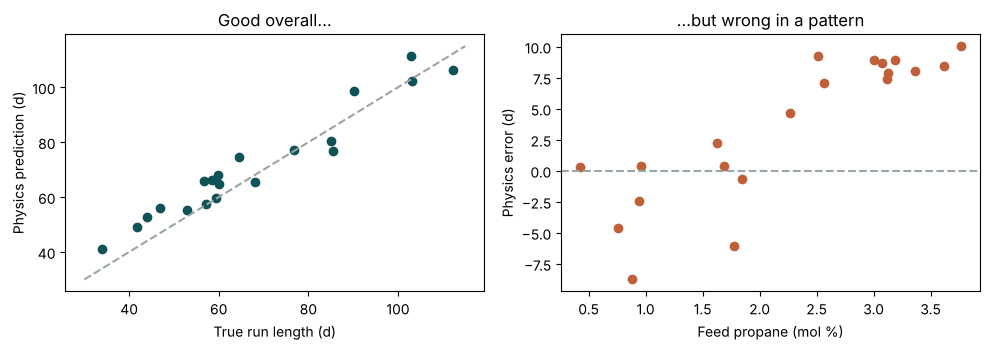

In [8]:
test_truth = pd.read_csv('data/hidden/test_true_daily.csv')    # audit view only
rows = []
for rid, g in test_truth.groupby('run_id'):
    conds = list(zip(g.feed, g.ratio, g.cot))
    pred, _ = coke.simulate_run(lambda day: conds[min(int(day), len(conds) - 1)], A_c)
    true_len = T['runs'].set_index('run_id').run_length_days[rid]
    rows.append(dict(run_id=rid, true=true_len, physics=pred, propane=g.propane.iloc[0] * 100))
chk = pd.DataFrame(rows); chk['error'] = chk.physics - chk.true
print(f"Physics-only, best case: mean absolute error {chk.error.abs().mean():.1f} days, bias {chk.error.mean():+.1f} days")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(chk.true, chk.physics, color='#0f5257'); lim = [30, 115]; ax[0].plot(lim, lim, color='#9aa5a6', ls='--')
ax[0].set_xlabel('True run length (d)'); ax[0].set_ylabel('Physics prediction (d)'); ax[0].set_title('Good overall...')
ax[1].scatter(chk.propane, chk.error, color='#c0603a'); ax[1].axhline(0, color='#9aa5a6', ls='--')
ax[1].set_xlabel('Feed propane (mol %)'); ax[1].set_ylabel('Physics error (d)'); ax[1].set_title('...but wrong in a pattern')
fig.tight_layout(); plt.show()

**Result.** The physics model is good but systematically optimistic, and its error grows with feed propane,
which it does not know about. This is exactly the situation a hybrid is built for: physics carries the trend,
ML learns the pattern in the residual. Whether the hybrid *actually* finds it from sparse data is Step 4's job,
and we will report the result honestly either way.

**Limitations of the synthetic plant.** The true furnace decokes exactly when the *true* TMT hits 1100 °C; real operators
decide from noisy readings and schedules. Operating policies are random within plausible ranges, not taken from a real plant.
All numbers are illustrative.

### Council review of Step 3

| Adviser | Challenge | Answer in this step |
|---|---|---|
| **Contrarian** | "Synthetic data is rigged for the hybrid." | Partly answered. The truth has three effects that change run length and two that change only measurements; physics alone is shown to be imperfect. But the truth shares the physics model's structure, so the result applies to a good physics model, not to any plant. |
| **First principles** | "What exactly will the models predict?" | Two questions, both supported by this data: (a) run length at start of campaign from the operating plan; (b) remaining days mid-campaign from the data so far. (b) is what operators need. |
| **Expansionist** | "Can this be reused?" | `plant_truth.py` is a data generator for ProcessGuard demos and the Interlock Checker; sensor frequency and noise are parameters. |
| **Outsider** | "Would a furnace engineer accept these data?" | Unknown until asked. Pyrometer frequency (weekly) and propane levels are the two assumptions to check with engineers. |
| **Executor** | "What's next on Monday?" | Step 4: physics-only (one recalibration factor allowed), ML-only (gradient boosting), hybrid (physics + ML on the residual), trained on 2, 4, 8, 16 and 30 campaigns. |

**Chairman:** Step 3 is fit for purpose. Open risk: the realism of sensor assumptions. Resolve it with the engineer outreach, not by guessing.

## Step 4 · Physics vs ML vs hybrid

### Three questions an operator asks
| | Question | What the models know |
|---|---|---|
| **(a) Start** | "How long will this campaign last?" | operating plan + first propane lab sample |
| **(b) Day 21 forecast** | "How many days are left?" | 21 days of DCS data, 3 pyrometer readings, 3 propane samples; future assumed = last week |
| **(c) Day 21 what-if** | "If I run at *these* conditions, how many days are left?" | same as (b) **plus** the conditions for the rest of the run |

(c) separates two things that (b) mixes: *is the model right?* and *can it guess what operators will do next?*

### Five models, same data
| Model | In plain words |
|---|---|
| **physics** | `coke.py` with **one** number tuned on the training campaigns: a factor on the coking rate. What an engineer does when "tuning" a model. |
| **ml_ridge** | straight-line fit on measured features (DCS averages, pyrometer readings, propane). No physics. |
| **ml_gbm** | gradient boosting: many small decision trees. No physics. Powerful with lots of data. |
| **hybrid_residual** | physics prediction **+** a small model that learns the physics *error* from propane and the tube-temperature offset. "Correct the output." |
| **hybrid_param** | ML predicts the physics *coking factor* for each campaign, then physics runs with it. "Learn the physics parameter." |

### How each model decides how complex to be
Every model chooses its penalty by **leave-one-out** on its *training* campaigns: each campaign is hidden once
and predicted by the others. Two selection rules are compared:
- **cautious (main rule):** the one-standard-error rule: take the *simplest* option within one standard error of the best
  (Hastie, Tibshirani & Friedman, *Elements of Statistical Learning*, §7.10). For the hybrids "simplest" means "no correction".
- **aggressive (sensitivity check):** take the option with the lowest leave-one-out error.

The test campaigns are never used for any choice. Training sets of 2, 4, 8, 16 and 30 campaigns; each small size is drawn
20 times at random and the errors averaged.

**History of honest fixes** (kept because they are part of the result): a fixed penalty first made the residual hybrid worse
than physics with 2 campaigns; plain leave-one-out then picked complex options on ties; the physics factor and the
parameter hybrid used different loss functions. Each was fixed by a general rule, never by looking for a better test score.

Learning curves take about 15 minutes to compute; they are cached in `data/derived/` (`python3 models.py` recomputes).

In [9]:
import models as M, warnings
warnings.filterwarnings('ignore')
LC = {(q, r): M.learning_curve_cached(q, r) for q in 'abc' for r in ['1se', 'min']}
for q, title in [('a', 'start'), ('b', 'day-21 forecast'), ('c', 'day-21 what-if')]:
    t = LC[(q, '1se')].groupby(['n_train', 'model']).mae.mean().unstack()[['physics', 'ml_ridge', 'ml_gbm', 'hybrid_residual', 'hybrid_param']]
    print(f"({q}) {title}: mean absolute error on 20 test campaigns, days (cautious rule)")
    print(t.round(1).to_string(), '\n')

(a) start: mean absolute error on 20 test campaigns, days (cautious rule)
model    physics  ml_ridge  ml_gbm  hybrid_residual  hybrid_param
n_train                                                          
2           13.8      21.5    20.8             13.8          13.8
4           13.7      19.4    18.9             14.4          14.6
8           12.8      17.6    17.1             12.9          12.9
16          12.6      15.6    15.3             12.5          12.5
30          12.4      14.0    14.5             12.4          12.5 

(b) day-21 forecast: mean absolute error on 20 test campaigns, days (cautious rule)
model    physics  ml_ridge  ml_gbm  hybrid_residual  hybrid_param
n_train                                                          
2           10.6      21.5    20.7             10.6          10.6
4            9.7      19.1    18.3             10.8          10.9
8            9.1      17.0    14.6              8.9           9.1
16           9.0      13.2    11.8              

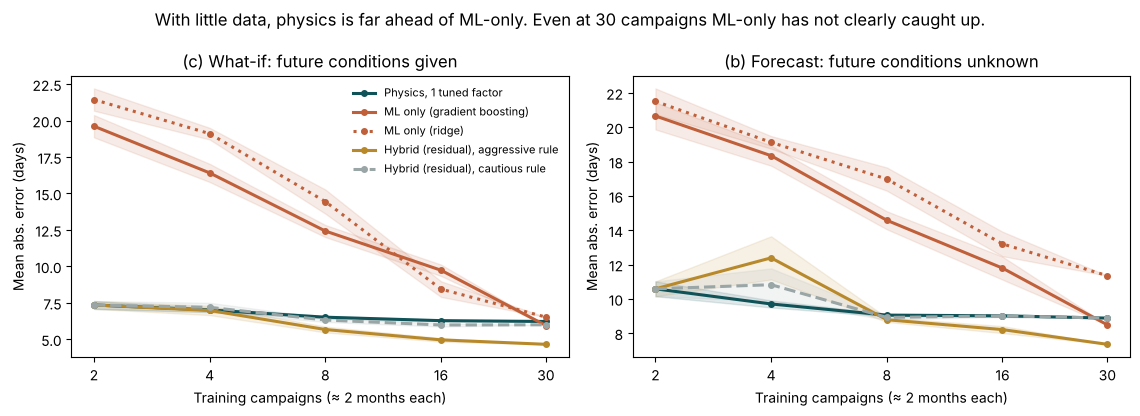

In [10]:
def curve(ax, q, title):
    lines = [('physics', '1se', 'Physics, 1 tuned factor', '#0f5257', '-'),
             ('ml_gbm', '1se', 'ML only (gradient boosting)', '#c0603a', '-'),
             ('ml_ridge', '1se', 'ML only (ridge)', '#c0603a', ':'),
             ('hybrid_residual', 'min', 'Hybrid (residual), aggressive rule', '#b8892b', '-'),
             ('hybrid_residual', '1se', 'Hybrid (residual), cautious rule', '#9aa5a6', '--')]
    for model, rule, label, col, ls in lines:
        g = LC[(q, rule)]; g = g[g.model == model].groupby('n_train').mae
        m, se = g.mean(), g.std().fillna(0) / np.sqrt(g.count())
        ax.plot(m.index, m.values, ls, color=col, lw=2.2, marker='o', ms=4, label=label)
        ax.fill_between(m.index, m - se, m + se, color=col, alpha=0.12)
    ax.set_xscale('log', base=2); ax.set_xticks([2, 4, 8, 16, 30]); ax.set_xticklabels([2, 4, 8, 16, 30])
    ax.set_xlabel('Training campaigns (≈ 2 months each)'); ax.set_ylabel('Mean abs. error (days)'); ax.set_title(title)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
curve(ax[0], 'c', '(c) What-if: future conditions given'); curve(ax[1], 'b', '(b) Forecast: future conditions unknown')
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle('With little data, physics is far ahead of ML-only. Even at 30 campaigns ML-only has not clearly caught up.')
fig.tight_layout(); plt.show()

### Confirmation on fresh data

Looking at curves and then choosing a story is how people fool themselves. So a **new set of 20 campaigns**
(different random seed, `tools/make_confirm.py`) was generated *after* the results above and used once, with no changes.
Below, all models are trained on the 30 history campaigns and tested twice: pooled over **test + confirmation = 40 campaigns**,
and on the **fresh confirmation set alone**. The second is the clean check, because the test set also guided some method choices.
The bars show how many days each model gains over tuned physics, with a 95 % bootstrap confidence interval
(resampling the 40 campaigns 5 000 times). If the interval crosses zero, the gain is **not proven**.

In [11]:
H, ph = M.features('history'), M.physics_table('history')
rng = np.random.default_rng(1); rows = []
for q in ['c', 'b']:
    for rule in ['1se', 'min']:
        M.RULE = rule; errs = {}
        for split in ['test', 'confirm']:
            Tq = M.features(split); preds, _ = M.fit_predict(H, Tq, ph, M.physics_table(split), q)
            for k, v in preds.items(): errs.setdefault(k, []).extend(np.abs(v - Tq[M.TARGET[q]].values))
        e = {k: np.array(v) for k, v in errs.items()}
        for other in ['hybrid_residual', 'hybrid_param', 'ml_gbm']:
            d = e['physics'] - e[other]; b = [rng.choice(d, len(d)).mean() for _ in range(5000)]
            rows.append(dict(question=q, rule=rule, model=other, mae=e[other].mean(), physics_mae=e['physics'].mean(),
                             gain=d.mean(), lo=np.percentile(b, 2.5), hi=np.percentile(b, 97.5)))
M.RULE = '1se'
CI = pd.DataFrame(rows)
print('Pooled 40 campaigns (test + confirmation):')
print(CI.round(2).to_string(index=False))
# the clean check: the fresh confirmation set alone (the test set also guided some method choices)
rows2 = []
for q in ['c', 'b']:
    for rule in ['1se', 'min']:
        M.RULE = rule; Tq = M.features('confirm'); preds, _ = M.fit_predict(H, Tq, ph, M.physics_table('confirm'), q)
        e = {k: np.abs(v - Tq[M.TARGET[q]].values) for k, v in preds.items()}
        for other in ['hybrid_residual', 'hybrid_param', 'ml_gbm']:
            d = e['physics'] - e[other]; b = [rng.choice(d, len(d)).mean() for _ in range(5000)]
            rows2.append(dict(question=q, rule=rule, model=other, gain=d.mean(), pct=d.mean() / e['physics'].mean() * 100,
                              lo=np.percentile(b, 2.5), hi=np.percentile(b, 97.5)))
M.RULE = '1se'
print('\nFresh confirmation set only (20 campaigns, used once):')
print(pd.DataFrame(rows2).round(2).to_string(index=False))

Pooled 40 campaigns (test + confirmation):
question rule           model  mae  physics_mae  gain    lo   hi
       c  1se hybrid_residual 5.07         5.16  0.09 -0.26 0.44
       c  1se    hybrid_param 5.14         5.16  0.02 -0.01 0.05
       c  1se          ml_gbm 6.23         5.16 -1.07 -3.01 0.98
       c  min hybrid_residual 4.08         5.16  1.08  0.43 1.70
       c  min    hybrid_param 3.89         5.16  1.28  0.14 2.49
       c  min          ml_gbm 6.23         5.16 -1.07 -3.06 1.10
       b  1se hybrid_residual 8.80         8.80  0.00  0.00 0.00
       b  1se    hybrid_param 8.83         8.80 -0.04 -0.14 0.08
       b  1se          ml_gbm 9.05         8.80 -0.26 -2.53 1.89
       b  min hybrid_residual 8.10         8.80  0.69 -0.33 1.70
       b  min    hybrid_param 8.16         8.80  0.63 -0.69 1.87
       b  min          ml_gbm 9.05         8.80 -0.26 -2.52 1.84



Fresh confirmation set only (20 campaigns, used once):
question rule           model  gain    pct    lo    hi
       c  1se hybrid_residual -0.04  -0.96 -0.52  0.47
       c  1se    hybrid_param  0.03   0.66 -0.02  0.07
       c  1se          ml_gbm -2.42 -58.87 -4.67 -0.37
       c  min hybrid_residual  0.59  14.36 -0.32  1.43
       c  min    hybrid_param  0.31   7.48 -1.27  1.88
       c  min          ml_gbm -2.42 -58.87 -4.67 -0.38
       b  1se hybrid_residual  0.00   0.00  0.00  0.00
       b  1se    hybrid_param -0.11  -1.21 -0.23  0.03
       b  1se          ml_gbm -0.90 -10.38 -3.61  1.53
       b  min hybrid_residual -0.15  -1.67 -1.53  1.22
       b  min    hybrid_param -0.00  -0.01 -1.59  1.70
       b  min          ml_gbm -0.90 -10.38 -3.48  1.53


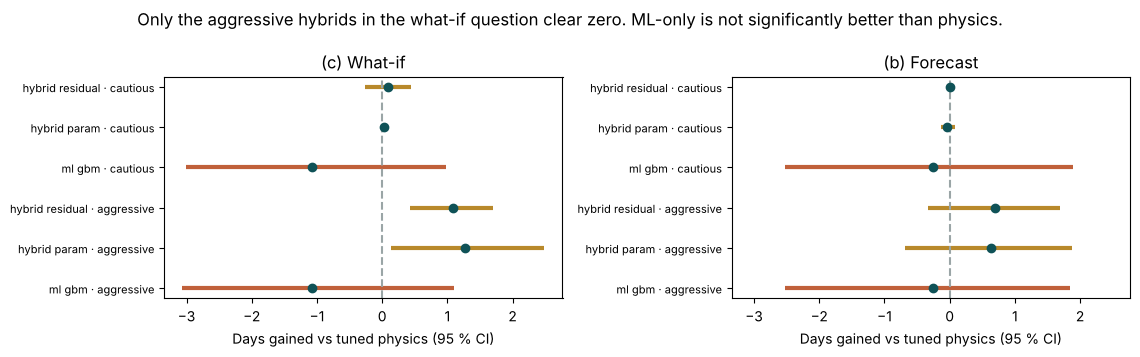

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6), sharex=True)
for a, q, title in [(ax[0], 'c', '(c) What-if'), (ax[1], 'b', '(b) Forecast')]:
    s = CI[CI.question == q].reset_index(drop=True)
    labels = [f"{r.model.replace('_', ' ')} · {'aggressive' if r.rule == 'min' else 'cautious'}" for r in s.itertuples()]
    cols = ['#c0603a' if 'ml' in m else '#b8892b' for m in s.model]
    a.errorbar(s.gain, range(len(s)), xerr=[s.gain - s.lo, s.hi - s.gain], fmt='o', color='#0f5257', ecolor=cols, elinewidth=3, capsize=0)
    a.axvline(0, color='#9aa5a6', ls='--'); a.set_yticks(range(len(s))); a.set_yticklabels(labels, fontsize=8)
    a.set_xlabel('Days gained vs tuned physics (95 % CI)'); a.set_title(title); a.invert_yaxis()
fig.suptitle('Only the aggressive hybrids in the what-if question clear zero. ML-only is not significantly better than physics.')
fig.tight_layout(); plt.show()

### Did the hybrid learn real physics?

A black-box model gives a number. The parameter hybrid gives a *physical* answer we can check: how much feed propane
raises the coking rate. Here we compare it with the hidden truth (audit only; the model never saw it).

Learned by the hybrid: +5.6 % coking rate per mol % propane
Hidden truth:          +6.7 % per mol % propane (at the average propane level)


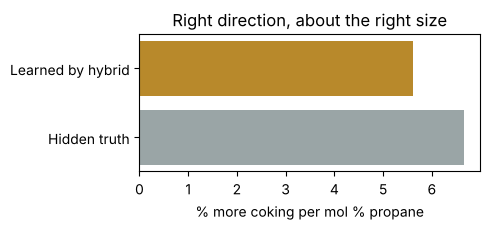

In [13]:
import json
M.RULE = 'min'
Hc = M.features('history'); X = np.column_stack([Hc.propane_mean, [ph[r]['tmt_offset'] for r in Hc.run_id]])
_ = M.fit_predict_param(ph, Hc.run_id, X, Hc.remaining.values, ph, Hc.run_id, X, 'c')
M.RULE = '1se'
fit = M.fit_predict_param.last
learned = fit['theta'][1] / fit['sd'][0] * 0.01 * 100                      # % coking-rate change per 1 mol % propane
truth_p = json.load(open('data/hidden/truth_params.json'))['TRUTH']          # audit view only
x = Hc.propane_mean.mean(); true_eff = truth_p['propane_gain'] / (1 + truth_p['propane_gain'] * x) * 0.01 * 100
print(f"Learned by the hybrid: +{learned:.1f} % coking rate per mol % propane")
print(f"Hidden truth:          +{true_eff:.1f} % per mol % propane (at the average propane level)")
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(['Hidden truth', 'Learned by hybrid'], [true_eff, learned], color=['#9aa5a6', '#b8892b'])
ax.set_xlabel('% more coking per mol % propane'); ax.set_title('Right direction, about the right size')
fig.tight_layout(); plt.show()

### Result in plain words

1. **Even with 30 campaigns (≈ five years of one furnace), ML alone had not clearly caught up with a tuned physics model.**
   With 2–8 campaigns it was 1.3–3× worse. At 30 campaigns it was slightly better on the test set but about 2.4 days
   worse on the fresh confirmation set (significant), and worse on the start-of-campaign question throughout.
2. **A physics model with one tuned factor is the strongest single tool** when data is sparse.
3. **The hybrid's gain is small and not proven on fresh data.** On the test set the aggressive hybrids looked 25–36 %
   better in what-if use; on the fresh confirmation set alone the gain is 0.3–0.6 days (7–14 %) with intervals that
   include zero. Pooled it looks like about a day, but that leans on the test set, which also guided method choices.
   The parameter hybrid **recovers the propane effect** (+5.6 % per mol % vs +6.7 % true; a rough bootstrap gives
   2–10 %, so the closeness is partly luck) and gives the pyrometer readings almost no weight.
4. **In the true forecast no model was significantly better than physics.** The biggest error source is what operators
   do after day 21, not the model. That points the € step toward *what-if* use: "if I hold COT at X, I have Y days."
5. **The selection rule matters as much as the model.** The cautious rule stays within about 1 day of physics but rarely
   corrects. The aggressive rule corrects, but with very little data it can be clearly worse than physics: the parameter
   hybrid with 2 campaigns, and the residual hybrid with 4 campaigns in the forecast (2.7 days worse). With fewer than
   about 8 campaigns, plain tuned physics is the safe choice.

**Honest caveats.** One synthetic plant that shares the physics model's structure; small held-back sets; the bootstrap
does not include training-set variation; at 30 training campaigns there is only one training set (no band); the
aggressive-rule configuration was identified after seeing results. All values illustrative.

### Council review of Step 4

| Adviser | Challenge | Answer |
|---|---|---|
| **Contrarian** | "You kept fixing things until the hybrid looked good." | Every fix was a general rule applied to all models; a fresh confirmation set was used once and *shrank* the hybrid's gain to 0.3–0.6 days, not proven. That smaller number is the headline. |
| **First principles** | "Is the hybrid the point?" | No. The robust finding is about data: with sparse data, physics structure is worth more than ML flexibility, and future operation dominates forecast error. |
| **Expansionist** | "What's the bigger story?" | (1) What-if tool for operators, the € case for Step 5. (2) *Value of information:* would daily TMT (thermocouples) beat better ML? That's one parameter in `plant_truth.py`. |
| **Outsider** | "Would a plant believe this?" | Plants already tune physics models (e.g. SPYRO-based tools). The message "ML alone needs years of data; physics + light learning works now" matches how plants actually operate. |
| **Executor** | "What's next?" | Step 5: € value of the what-if use, e.g. choosing COT for a target run length, priced with explicit, stated assumptions. |

**Chairman:** Step 4 delivers an honest, defensible result: *physics first, ML second, hybrid where data allows.*
Do not market it as "hybrid beats everything". The open risk is a single synthetic plant; the value-of-information test is the
cheapest next experiment.

## Step 5 · What is a better prediction worth, in euros?

**Rule:** a prediction earns money only if it changes a decision. Two decisions:

- **Case A: when to schedule the decoke** (compares the models). On day 21 the model predicts the days left. Because it can be
  wrong, planners decoke *early* by a safety margin, sized so that only about 1 campaign in 20 would hit the tube limit first.
  A better model needs a smaller margin, which means longer campaigns, fewer decokes per year, and less downtime and decoke cost.
- **Case B: which COT to run** (what the model is *for*). A hotter COT makes more ethylene per hour but cokes faster.
  The physics model turns each COT into a run length, so we can see the COT that earns most over a whole cycle.

### Economic inputs

| Input | Value used | Source / status |
|---|---|---|
| Cash margin per t ethylene | 15 ¢/lb → **€287/t** (base); 19 ¢/lb → €364/t; 30 ¢/lb → €574/t | RBN Energy ethane-cracker margin: long-term average ~15 ¢/lb, ~19 ¢/lb in June 2026, ~30 ¢/lb at the April 2026 peak. US Gulf basis. |
| Exchange rate | 1 € = 1.152 $ | OPIS, April 2026 European ethylene settlement (€1,595 = $1,837) |
| Decoke duration | **2 days** (range 1–3) | Imubit; Prismecs: "1 to 3 days" |
| Direct cost per decoke | **€50k** (range €20–150k) | **Assumption.** No public source found. Covers steam, air, fuel, crew, coil life used. |
| Spare furnace? | both cases shown | Imubit: plants run 6–12 furnaces, one in decoke and one on hot standby. With a spare, decoke days lose no production. |
| Ethylene from this furnace | **383 t/day** | coil model, design point |

**Simplifications, stated plainly:** unconverted ethane is recycled, so the margin per tonne of ethylene is held constant;
fuel cost of a hotter COT, coil-life loss from thermal cycling, and downstream limits (cracked-gas compressor) are not modelled
except through the decoke-cost assumption.

In [14]:
import value as V
print(f"Base margin {V.ECON['margin']:.0f} EUR/t ethylene x {V.design_ethylene_tpd():.0f} t/day "
      f"= {V.ECON['margin'] * V.design_ethylene_tpd() / 1e3:.0f} kEUR per cracking day for one furnace")
print(f"One decoke in a furnace-limited plant: 2 days x that + 50 kEUR direct "
      f"= {(2 * V.ECON['margin'] * V.design_ethylene_tpd() + 50e3) / 1e3:.0f} kEUR")

Base margin 287 EUR/t ethylene x 383 t/day = 110 kEUR per cracking day for one furnace
One decoke in a furnace-limited plant: 2 days x that + 50 kEUR direct = 270 kEUR


### Case A · Decoke planning with each model

How the code works:
1. Every model is trained on the 30 history campaigns and predicts the days left on day 21 (what-if question) for the
   40 held-back campaigns (test + confirmation).
2. **Cross-fitting:** the safety margin is sized on one held-back set and judged on the other, then swapped. The margin never
   sees the campaigns it is judged on.
3. Two ways to size a 95 % margin from 20 campaigns:
   - **normal:** mean error + 1.645 × standard deviation (main method; stable, assumes roughly bell-shaped errors);
   - **empirical:** the 95 % point of the errors themselves (no assumption, but with 20 campaigns it is close to
     "the second-worst case" and very noisy).
4. Days decoked too early are turned into € per furnace-year by comparing with perfect foresight.

In [15]:
import pickle
H, ph = M.features('history'), M.physics_table('history'); RES = {}
for rule in ['min', '1se']:
    M.RULE = rule
    for split in ['test', 'confirm']:
        Ts = M.features(split); pr, _ = M.fit_predict(H, Ts, ph, M.physics_table(split), 'c')
        for k, v in pr.items(): RES[(rule, split, k)] = (v, Ts.remaining.values, Ts.run_length.values)
M.RULE = '1se'
CANDIDATES = [('1se', 'physics', 'Physics, 1 tuned factor'), ('min', 'hybrid_param', 'Hybrid (parameter)'),
              ('min', 'hybrid_residual', 'Hybrid (residual)'), ('1se', 'ml_gbm', 'ML only (boosting)'), ('1se', 'ml_ridge', 'ML only (ridge)')]
rows = []
for rule, model, label in CANDIDATES:
    sets = {s: RES[(rule, s, model)] for s in ['test', 'confirm']}
    for method in ['normal', 'empirical']:
        lim = V.case_a(sets, dict(spare_furnace=False), method); spa = V.case_a(sets, dict(spare_furnace=True), method)
        rows.append(dict(model=label, margin_method=method, safety_margin_d=lim['margin_days'], early_d=lim['early_days'],
                         hit_limit=f"{lim['late']}/{lim['n']}", keur_lost_furnace_limited=lim['eur_lost'] / 1e3,
                         keur_lost_spare_furnace=spa['eur_lost'] / 1e3))
CA = pd.DataFrame(rows)
print(CA.round(1).to_string(index=False))

                  model margin_method  safety_margin_d  early_d hit_limit  keur_lost_furnace_limited  keur_lost_spare_furnace
Physics, 1 tuned factor        normal             10.6     11.5      0/40                      316.3                     58.6
Physics, 1 tuned factor     empirical              5.7      6.8      3/40                      139.6                     25.9
     Hybrid (parameter)        normal              8.0      8.1      0/40                      193.6                     35.8
     Hybrid (parameter)     empirical              6.2      6.4      2/40                      132.1                     24.5
      Hybrid (residual)        normal              7.8      9.4      0/40                      237.2                     43.9
      Hybrid (residual)     empirical              5.5      7.1      2/40                      151.8                     28.1
     ML only (boosting)        normal              7.4     11.7      1/40                      342.3                  

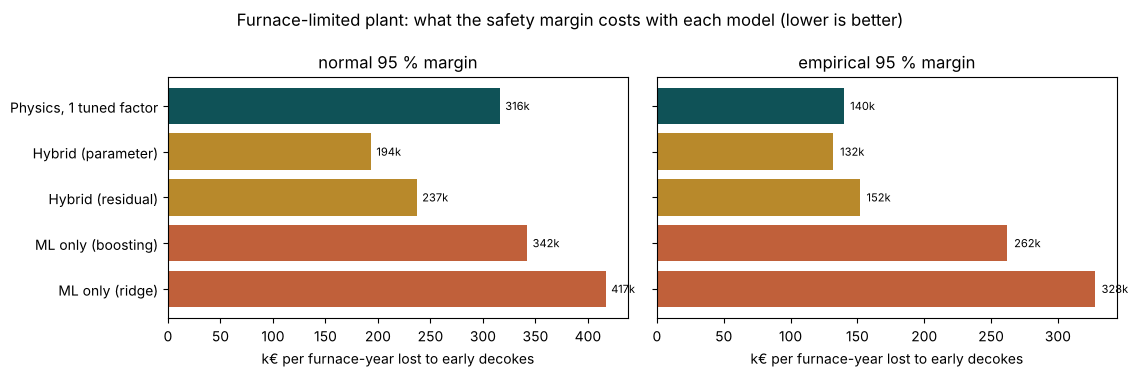

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for a, method in zip(ax, ['normal', 'empirical']):
    s = CA[CA.margin_method == method]
    cols = ['#0f5257' if 'Physics' in m else '#b8892b' if 'Hybrid' in m else '#c0603a' for m in s.model]
    a.barh(s.model, s.keur_lost_furnace_limited, color=cols)
    for y, v in enumerate(s.keur_lost_furnace_limited): a.text(v + 5, y, f'{v:.0f}k', va='center', fontsize=8)
    a.set_title(f'{method} 95 % margin'); a.set_xlabel('k€ per furnace-year lost to early decokes')
ax[0].invert_yaxis()
fig.suptitle('Furnace-limited plant: what the safety margin costs with each model (lower is better)')
fig.tight_layout(); plt.show()

**Case A result.**
- Early decoking for safety costs real money with **every** model: about **€130–420k per furnace-year** in a furnace-limited plant,
  and €25–80k when a spare furnace covers the decoke.
- **Hybrid vs physics:** with the normal margin the parameter hybrid saves about **€120k per furnace-year**; with the
  empirical margin, about **€8k**, effectively nothing. **The hybrid's € value is not robust:** it depends on how the margin
  is sized, and 40 campaigns are not enough to settle it. The honest statement is a range: **−€12k to +€123k per furnace-year**
  (the residual hybrid with the empirical margin is slightly worse than physics; furnace-limited, base prices; up to about
  €220k at the April 2026 peak margin), about €0–25k with a spare furnace.
- **ML-only (ridge) is the most expensive in both methods.** Boosting is close to physics with the normal margin, worse with
  the empirical one.
- With the normal margin no physics or hybrid campaign hit the limit (0/40; ML-only 1–2/40); with the empirical margin 2–3 of 40 did,
  close to the intended 1 in 20. The normal margin is safer than intended because the errors are not perfectly bell-shaped.

### Case B · Which COT earns most?

The physics model gives run length and ethylene per day for each COT. Per furnace-year:
**profit = cracking days × ethylene/day × margin − decokes per year × decoke cost.** The optimum is a balance between
more ethylene per hour and more decokes. Because coil-life loss is not modelled, the decoke cost is varied far above the
base value to show how the optimum moves when each decoke "costs" more.

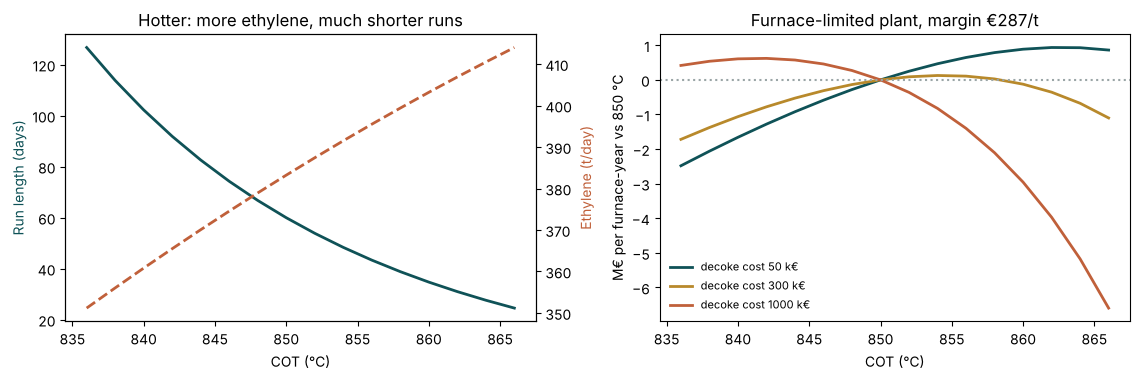

decoke cost    50 k€: best COT 862 °C, run   31 d, +0.94 M€/yr vs 850 °C
decoke cost   300 k€: best COT 854 °C, run   48 d, +0.13 M€/yr vs 850 °C
decoke cost  1000 k€: best COT 842 °C, run   92 d, +0.62 M€/yr vs 850 °C


In [17]:
A_c = coke.calibrate_A_c()
cots = list(range(836, 868, 2))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
base = V.cot_tradeoff(cots, A_c)
ax[0].plot(cots, [r['run_days'] for r in base], color='#0f5257', lw=2); ax[0].set_ylabel('Run length (days)', color='#0f5257')
a2 = ax[0].twinx(); a2.plot(cots, [r['ethylene_tpd'] for r in base], color='#c0603a', lw=2, ls='--'); a2.set_ylabel('Ethylene (t/day)', color='#c0603a')
ax[0].set_xlabel('COT (°C)'); ax[0].set_title('Hotter: more ethylene, much shorter runs')
opt = []
for cost, col in [(50e3, '#0f5257'), (300e3, '#b8892b'), (1e6, '#c0603a')]:
    rows = V.cot_tradeoff(cots, A_c, econ=dict(decoke_cost=cost)); ref = [r for r in rows if r['cot'] == 850][0]['eur_per_year']
    ax[1].plot(cots, [(r['eur_per_year'] - ref) / 1e6 for r in rows], color=col, lw=2, label=f'decoke cost {cost/1e3:.0f} k€')
    best = max(rows, key=lambda r: r['eur_per_year']); opt.append((cost, best['cot'], best['run_days'], (best['eur_per_year'] - ref) / 1e6))
ax[1].axhline(0, color='#9aa5a6', ls=':'); ax[1].set_xlabel('COT (°C)'); ax[1].set_ylabel('M€ per furnace-year vs 850 °C')
ax[1].set_title('Furnace-limited plant, margin €287/t'); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
for cost, c, run, gain in opt:
    print(f"decoke cost {cost/1e3:5.0f} k€: best COT {c} °C, run {run:4.0f} d, {gain:+.2f} M€/yr vs 850 °C")

**Case B result.** With the base assumptions the model points to a hotter COT (about 860 °C, roughly 30-day runs) worth about
+€0.9M per furnace-year over 850 °C. **Do not read that as a recommendation.** The model leaves out coil life lost to thermal
cycling, fuel cost and downstream limits, all of which push the optimum down; as the decoke cost rises, the optimum moves
down: 854 °C at €300k per decoke, 842 °C at €1M. The robust insight is the **shape**: with base costs the curve is flat near
the top (856–866 °C within 0.6 %), so small COT moves cost little, while running far too cold (836–840 °C) gives away
€1.6–2.5M per furnace-year in this model. Where the optimum sits depends on plant costs this model does not know.
This is how a furnace engineer would actually use the model: as a what-if tool for the trade-off, with plant-specific costs.

### Sensitivity: how much does the hybrid-vs-physics € depend on the inputs?

In [18]:
sets_p = {s: RES[('1se', s, 'physics')] for s in ['test', 'confirm']}
sets_h = {s: RES[('min', s, 'hybrid_param')] for s in ['test', 'confirm']}
cases = [('Base (15 ¢/lb, 2 d, 50 k€, no spare)', {}), ('Margin 19 ¢/lb (Jun 2026)', dict(margin=V.margin_eur_per_t(19))),
         ('Margin 30 ¢/lb (Apr 2026 peak)', dict(margin=V.margin_eur_per_t(30))), ('Decoke 1 day', dict(decoke_days=1.0)),
         ('Decoke 3 days', dict(decoke_days=3.0)), ('Decoke cost 20 k€', dict(decoke_cost=20e3)),
         ('Decoke cost 150 k€', dict(decoke_cost=150e3)), ('Spare furnace available', dict(spare_furnace=True))]
rows = []
for name, econ in cases:
    r = dict(case=name)
    for method in ['normal', 'empirical']:
        r[f'hybrid saves, {method} (k€/yr)'] = (V.case_a(sets_p, econ, method)['eur_lost'] - V.case_a(sets_h, econ, method)['eur_lost']) / 1e3
    rows.append(r)
print(pd.DataFrame(rows).round(0).to_string(index=False))

                                case  hybrid saves, normal (k€/yr)  hybrid saves, empirical (k€/yr)
Base (15 ¢/lb, 2 d, 50 k€, no spare)                         123.0                              8.0
           Margin 19 ¢/lb (Jun 2026)                         149.0                              9.0
      Margin 30 ¢/lb (Apr 2026 peak)                         223.0                             14.0
                        Decoke 1 day                          76.0                              5.0
                       Decoke 3 days                         165.0                             10.0
                   Decoke cost 20 k€                         109.0                              7.0
                  Decoke cost 150 k€                         168.0                             10.0
             Spare furnace available                          23.0                              1.0


### Result in plain words

1. **Safety margins are expensive.** Decoking early "to be safe" costs €130–420k per furnace-year in a furnace-limited
   plant with any model. That is the money a better prediction competes for.
2. **The hybrid's extra value over physics is −€12k to +€123k per furnace-year** (furnace-limited, base prices; up to ~€220k at the
   April 2026 peak margin), depending on the hybrid type and how the safety margin is sized, then on the margin price. With a spare furnace
   it shrinks to €0–25k. **Not robust enough to claim one number.**
3. **The model's bigger job is what-if:** choosing COT is a trade-off worth millions per furnace-year in this model, but the
   optimum depends on costs the model does not contain (coil life, fuel, compressor limits). The robust lesson is the flat top
   and the steep cold side.
4. **The € number depends most on the assumptions, not the model:** whether a spare furnace exists, the margin, and the decoke cost.

**Honest caveats.** US Gulf ethane margin applied to a synthetic furnace; decoke cost is an assumption; compared with perfect
foresight; a campaign that hits the tube limit gets no extra cost; the annual figure averages per-campaign profit (an
approximation); 40 held-back campaigns; one synthetic plant; COT economics simplified. All values illustrative.

### Council review of Step 5

| Adviser | Challenge | Answer |
|---|---|---|
| **Contrarian** | "€ numbers in portfolios are always inflated." | The headline is a *range* (−€12k to +€123k), the margin method that flatters the hybrid is shown next to the one that doesn't, and the large Case B number is explicitly labelled as not a recommendation. |
| **First principles** | "Where does the money really come from?" | From fewer decokes per year. The margin decides how much, and the safety margin, not the model's average error, drives it. A model that shrinks the *tail* of its errors is worth more than one that lowers the average. |
| **Expansionist** | "What is the bigger lever?" | Safety margins cost €130–420k/yr per furnace with every model. Better *measurement* (daily TMT instead of weekly pyrometer) may beat better modelling, which is the value-of-information test. |
| **Outsider** | "Is this how plants think?" | Yes on the logic (decoke scheduling, spare furnaces, COT trade-off). No on precision: plants know their decoke cost, coil-life budget and compressor limit; this page only shows the method. |
| **Executor** | "What ships next?" | Step 6: the web page. Lead with the honest learning curve and the safety-margin cost; let the visitor change margin, decoke cost and spare furnace and see the € move. |

**Chairman:** Present the € story as *method + range*, never a single number. The strongest line for a reviewer: *"The money is in the safety
margin; physics gets you most of it with little data, and the hybrid's extra is small and not proven on fresh data, so it cannot
be priced precisely."*